**10. Analyze the performance of ensemble learning techniques such as Random Forest or Boosting on a suitable open-access dataset in comparison with a baseline machine learning model.**

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import AdaBoostClassifier

# 2 Load dataset

In [4]:
data = load_breast_cancer()

In [6]:
x_train= data.data
y = data.target

In [8]:
print(x.shape)
print(y.shape)

(569, 30)
(569,)


# 3 spliting dataset

In [13]:
x_train,x_test,y_train,y_test= train_test_split(x,y,random_state = 42, test_size = 0.2, stratify = y)

In [15]:
x_train.shape

(455, 30)

In [16]:
x_test.shape

(114, 30)

# 4. MOdles

In [25]:
models = {
    "descision_tree": DecisionTreeClassifier(random_state=42),
    "Random_forest": RandomForestClassifier(n_estimators = 100,random_state= 42),
    "Gradient_boosting": GradientBoostingClassifier(random_state = 42),
    "AdaBoost":AdaBoostClassifier(random_state=42)
}

In [32]:
results = {}

In [34]:
for name, model in models.items():
    model.fit(x_train,y_train)
    accuracy = model.score(x_test,y_test)

    #  corss validation in 5 fold

    cv_score = cross_val_score(
        model, x_train, y_train, cv=5
    ).mean()

    results[name] = accuracy

    print("\n", name)
    print("Test Accuracy:", round(accuracy * 100, 2), "%")
    print("5-Fold CV Accuracy:", round(cv_score * 100, 2), "%")


 descision_tree
Test Accuracy: 91.23 %
5-Fold CV Accuracy: 90.99 %

 Random_forest
Test Accuracy: 95.61 %
5-Fold CV Accuracy: 95.38 %

 Gradient_boosting
Test Accuracy: 95.61 %
5-Fold CV Accuracy: 95.6 %

 AdaBoost
Test Accuracy: 95.61 %
5-Fold CV Accuracy: 96.92 %


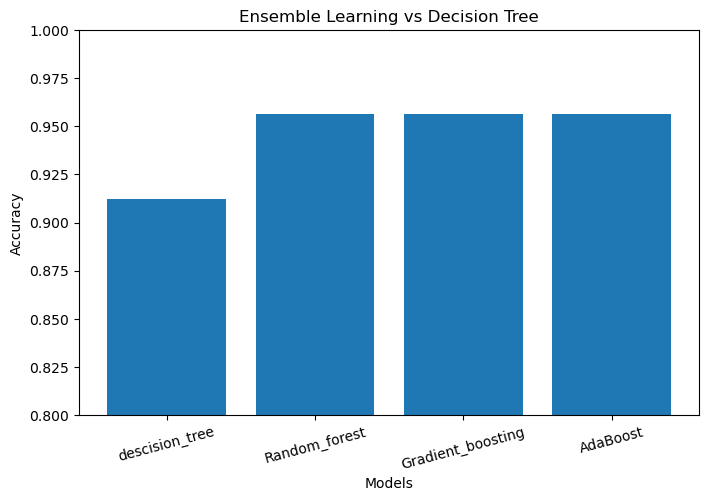

In [35]:
# Step 6: Plot accuracy comparison
plt.figure(figsize=(8, 5))

plt.bar(results.keys(), results.values())

plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.title("Ensemble Learning vs Decision Tree")

plt.ylim(0.8, 1.0)
plt.xticks(rotation=15)

plt.show()

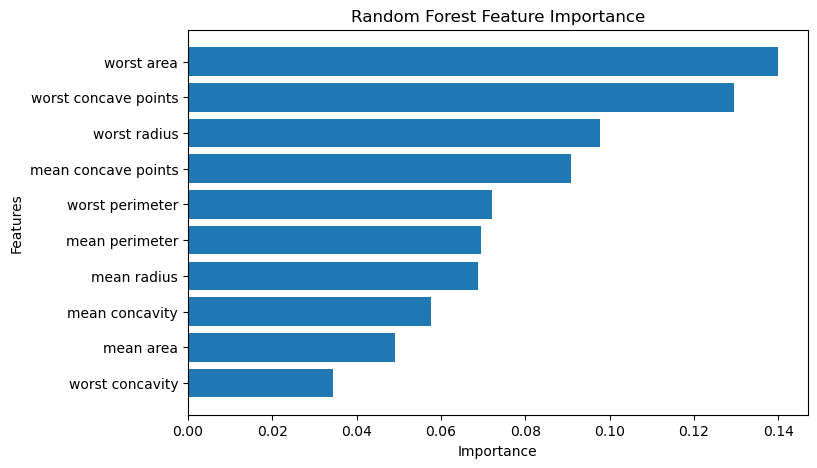

In [38]:
# Step 7: Random Forest Feature Importance
rf_model = models["Random_forest"]

importance = rf_model.feature_importances_

# Get top 10 important features
indices = np.argsort(importance)[-10:]

plt.figure(figsize=(8, 5))

plt.barh(
    range(10),
    importance[indices]
)

plt.yticks(
    range(10),
    data.feature_names[indices]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")

plt.show()

In [43]:
 models["Random_forest"].feature_importances_

array([0.06867599, 0.00958431, 0.06957388, 0.04917215, 0.00559816,
       0.01171465, 0.05763806, 0.09088475, 0.00466601, 0.00448887,
       0.01677021, 0.00521386, 0.0096331 , 0.03310446, 0.00349852,
       0.00597922, 0.00431035, 0.00409824, 0.00401198, 0.00444169,
       0.09769574, 0.01859665, 0.07222637, 0.14001599, 0.0124362 ,
       0.01860002, 0.03434013, 0.12952961, 0.00833452, 0.00516632])